# Parse TimeXNet stats - February 19, 2016
Select the optimal TimeXNet parameters

In [1]:
%pylab inline

import pandas as pd
import os

Populating the interactive namespace from numpy and matplotlib


## Configure directories

In [2]:
txn_stats_file = os.path.join('..','..','TimeXNet','results','020916','net_stats')

## Load the TimeXNet summary statistics file
TimeXNet paper suggests chooising the "sub-network with the highest number of source nodes and less than 1% unreliable edges (edge weight < 0.5)"

In the output file (per http://timexnet.hgc.jp/):
* Sources: Total number of "initial" genes in the predicted response network
* Edges: Total number of edges predicted in the response network
* Edges0.5: Total number of edges with reliability less than 0.5 predicted in the response network

We used a different PPI network so these thresholds are not applicable exactly

In [3]:
txn_df = pd.read_csv(txn_stats_file, sep='\t')
# Store the ratio of unreliable edges to total edges
txn_df['Unreliable0.5'] = txn_df.apply(lambda row: float(row['Edges0.5'])/float(row['Edges']), axis=1)
txn_df['Unreliable0.3'] = txn_df.apply(lambda row: float(row['Edges0.3'])/float(row['Edges']), axis=1)
txn_df.head()

,Gamma1,Gamma2,Nodes,Sources,Intermediates,Sinks,Predicted,Edges,Edges0.5,Edges0.3,Unreliable0.5,Unreliable0.3
0,0,0.0,530,42,75,94,319,568,175,26,0.308099,0.045775
1,0,0.5,791,60,90,97,544,976,302,92,0.309426,0.094262
2,0,1.0,942,64,91,98,689,1215,365,127,0.300412,0.104527
3,0,1.5,998,63,90,96,749,1286,359,181,0.279160,0.140747
4,0,2.0,1069,63,89,96,821,1382,398,204,0.287988,0.147612


## Explore the network sizes

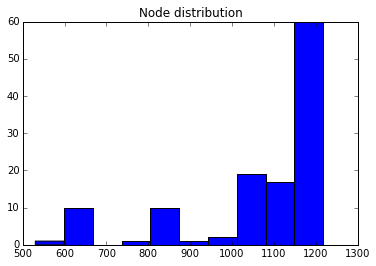

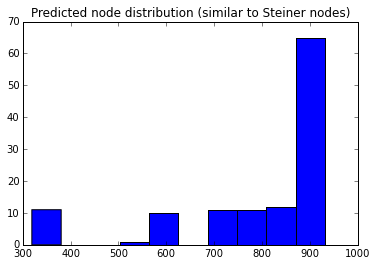

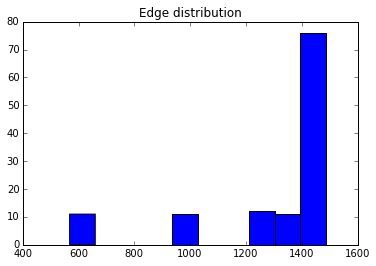

In [4]:
hist(txn_df['Nodes']);
title('Node distribution');

figure()
hist(txn_df['Predicted']);
title('Predicted node distribution (similar to Steiner nodes)');

figure()
hist(txn_df['Edges']);
title('Edge distribution');

## Assess the fraction of unreliable edges at a 0.5 threshold

0 reliable subnetworks at 0.5 threshold
Minimum ratio of unreliable edges (0.5 threshold) to total edges: 0.262069


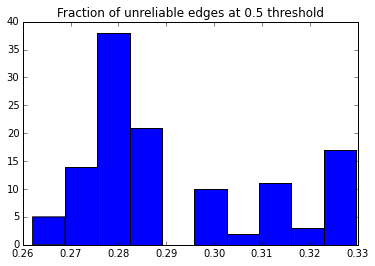

In [5]:
reliable_df = txn_df[txn_df['Unreliable0.5'] < 0.01]
print '%d reliable subnetworks at 0.5 threshold' % len(reliable_df)

min_unrel = min(txn_df['Unreliable0.5'])
print 'Minimum ratio of unreliable edges (0.5 threshold) to total edges: %f' % min_unrel

hist(txn_df['Unreliable0.5']);
title('Fraction of unreliable edges at 0.5 threshold');

## Assess the fraction of unreliable edges at a 0.3 threshold
Still are not any networks with < 1% unreliable edges but there are 11 networks with < 5% unreliable edges.  They are all of the networks with Gamma2 = 0.  Gamma2 controls the flow through the intermediate proteins, so is this constraint is not being enforced in these subnetworks?

0 reliable subnetworks at 0.3 threshold
Minimum ratio of unreliable edges (0.3 threshold) to total edges: 0.044234
11 reliable subnetworks at 0.3 threshold allowing 5% unreliable edges


,Gamma1,Gamma2,Nodes,Sources,Intermediates,Sinks,Predicted,Edges,Edges0.5,Edges0.3,Unreliable0.5,Unreliable0.3
0,0.0,0,530,42,75,94,319,568,175,26,0.308099,0.045775
11,0.5,0,612,47,78,130,357,622,201,28,0.323151,0.045016
22,1.0,0,621,48,79,136,358,629,204,28,0.324324,0.044515
33,1.5,0,628,48,79,137,364,634,209,29,0.329653,0.045741
44,2.0,0,625,48,78,137,362,632,206,29,0.325949,0.045886
55,2.5,0,626,48,79,137,362,632,206,29,0.325949,0.045886
66,3.0,0,627,48,79,137,363,632,207,29,0.327532,0.045886
77,3.5,0,624,48,79,137,360,632,206,30,0.325949,0.047468
88,4.0,0,628,48,79,137,364,634,209,30,0.329653,0.047319
99,4.5,0,625,48,78,137,362,633,207,28,0.327014,0.044234


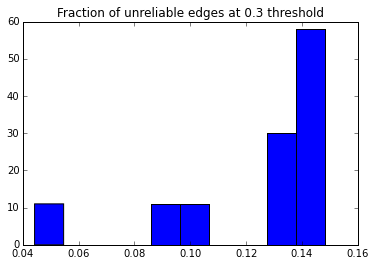

In [6]:
reliable_df = txn_df[txn_df['Unreliable0.3'] < 0.01]
print '%d reliable subnetworks at 0.3 threshold' % len(reliable_df)

min_unrel = min(txn_df['Unreliable0.3'])
print 'Minimum ratio of unreliable edges (0.3 threshold) to total edges: %f' % min_unrel

hist(txn_df['Unreliable0.3']);
title('Fraction of unreliable edges at 0.3 threshold');

reliable_relaxed_df = txn_df[txn_df['Unreliable0.3'] < 0.05]
print '%d reliable subnetworks at 0.3 threshold allowing 5%% unreliable edges' % len(reliable_relaxed_df)
reliable_relaxed_df

## Select the optimal parameters
A single network has the min unreliability score and the maximum number of sources (for the networks with unreliability scores < 5%) so choose that network.  From the edge distribution above, we see that it is one of the smallest networks.  There must be a flow threhsold applied to these edges counts because the output file for this network shows 1073 edges.

In [7]:
max_sources = max(reliable_relaxed_df['Sources'])
print 'Maximum number of sources in the reliable networks: %d' % max_sources

opt_row = reliable_relaxed_df[reliable_relaxed_df['Unreliable0.3'] == min_unrel]
assert (all(opt_row['Sources'] == max_sources))
print 'Optimal parameters'
opt_row

Maximum number of sources in the reliable networks: 48
Optimal parameters


,Gamma1,Gamma2,Nodes,Sources,Intermediates,Sinks,Predicted,Edges,Edges0.5,Edges0.3,Unreliable0.5,Unreliable0.3
99,4.5,0,625,48,78,137,362,633,207,28,0.327014,0.044234
